In [3]:
!pip install seaborn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 964.2 kB/s eta 0:00:10
   --- ------------------------------------ 0.8/9.5 MB 876.3 kB/s eta 0:00:10
   --- ------------------------------------ 0.8/9.5 MB 876.3 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.5 MB 853.1 kB/s eta 0:00:1


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
!pip install matplotlib


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = sns.load_dataset("taxis")

In [7]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [8]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [12]:
df[['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']].mode()

,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,credit card,Midtown Center,Upper East Side North,Manhattan,Manhattan


In [13]:
df['payment']=df['payment'].fillna(df['payment'].mode()[0])
df['pickup_zone']=df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['dropoff_zone']=df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['pickup_borough']=df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_borough']=df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

In [14]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [4]:
df['pickup']=pd.to_datetime(df['pickup'])
df['pickup'].head()

0   2019-03-23 20:21:09
1   2019-03-04 16:11:55
2   2019-03-27 17:53:01
3   2019-03-10 01:23:59
4   2019-03-30 13:27:42
Name: pickup, dtype: datetime64[us]

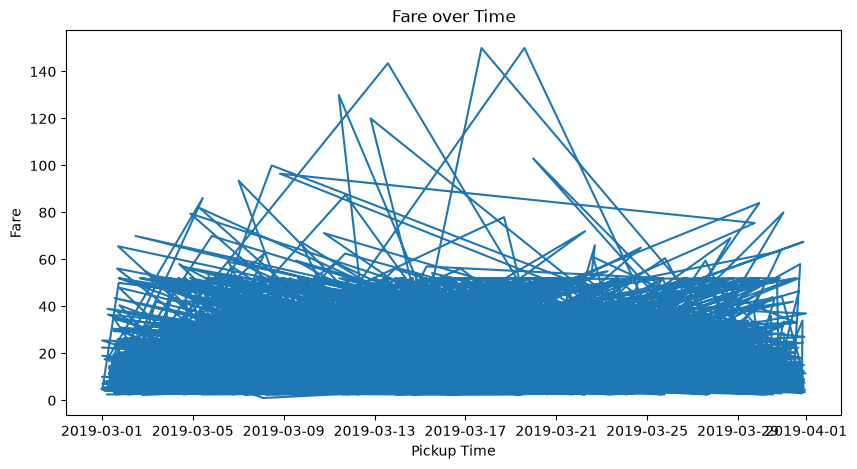

In [6]:
plt.figure(figsize=(10,5))
plt.plot(df['pickup'],df['fare'])
plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.title('Fare over Time')
plt.show()    
        

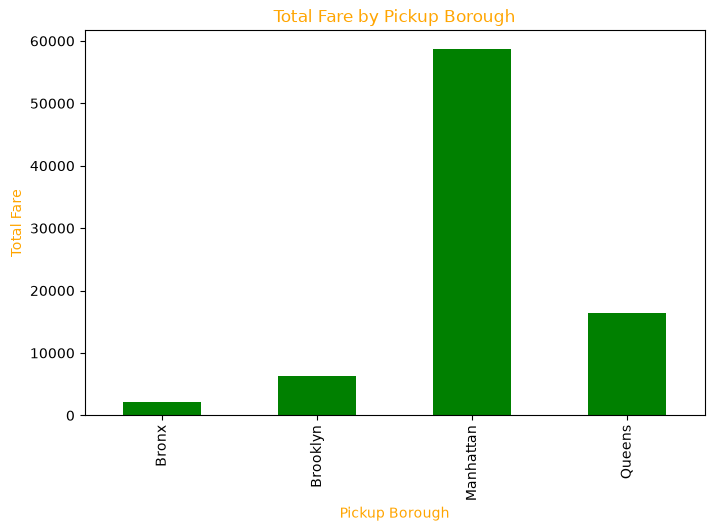

In [15]:
fare_by_borough=df.groupby('pickup_borough')['fare'].sum()
plt.figure(figsize=(8,5))
fare_by_borough.plot(kind='bar',color='green')
plt.xlabel('Pickup Borough',color='orange')
plt.ylabel('Total Fare',color='orange')
plt.title('Total Fare by Pickup Borough',color='orange')
plt.show()   

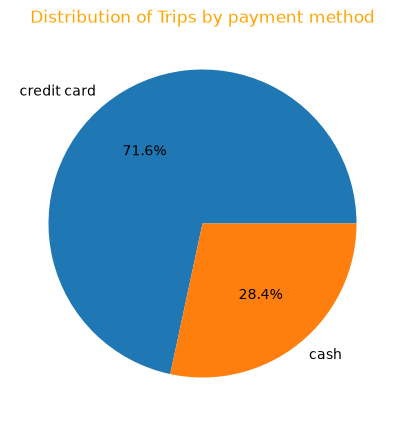

In [18]:
payment_counts=df['payment'].value_counts()
plt.figure(figsize=(8,5))
payment_counts.plot(kind='pie',autopct='%1.1f%%')

plt.title('Distribution of Trips by payment method',color='orange')
plt.show()   

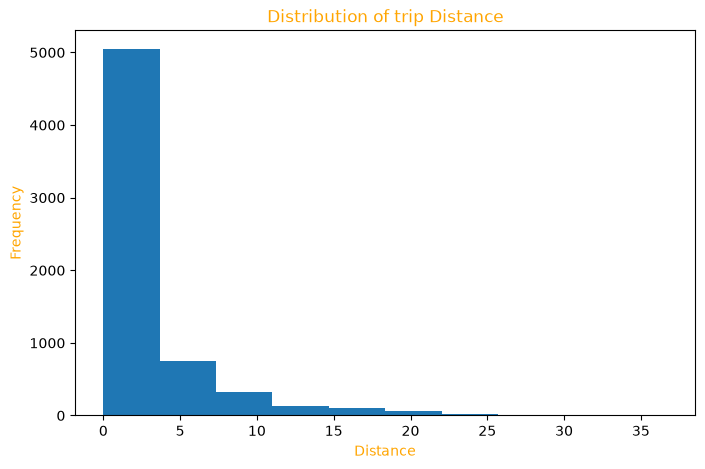

In [20]:
plt.figure(figsize=(8,5))
df['distance'].plot(kind='hist',bins=10)
plt.xlabel('Distance',color='orange')
plt.ylabel('Frequency',color='orange')
plt.title('Distribution of trip Distance',color='orange')
plt.show()   

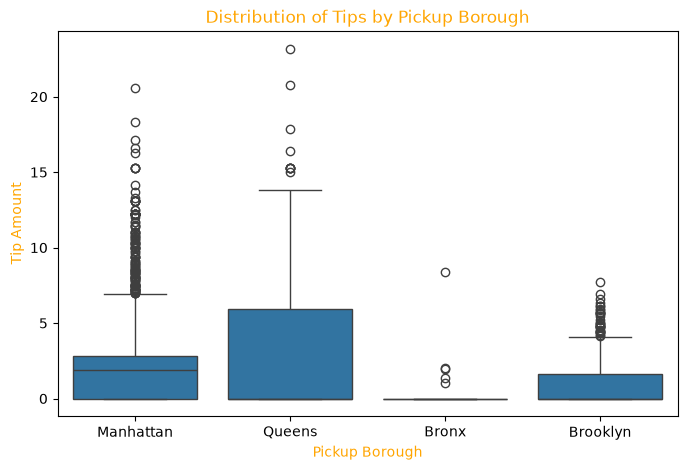

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(x='pickup_borough',y='tip',data=df)
plt.xlabel('Pickup Borough',color='orange')
plt.ylabel('Tip Amount',color='orange')
plt.title('Distribution of Tips by Pickup Borough',color='orange')
plt.show()   

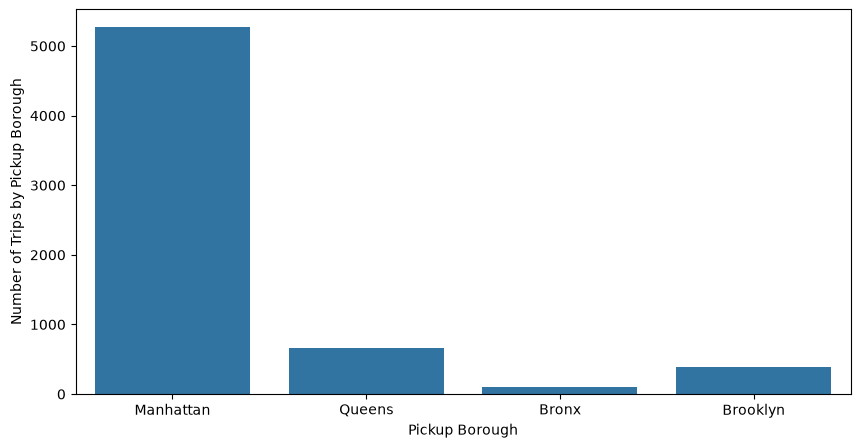

In [3]:
plt.figure(figsize=(10,5))
sns.countplot(x='pickup_borough',data=df)
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips by Pickup Borough')
plt.show()

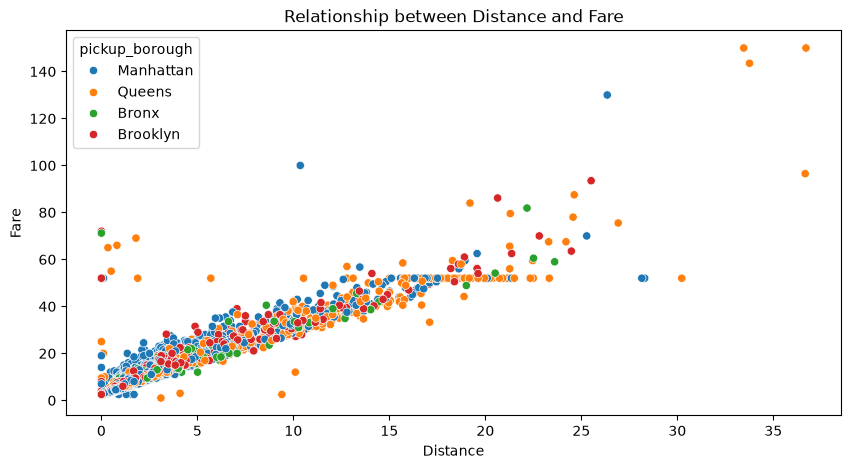

In [5]:
plt.figure(figsize=(10,5))
sns.scatterplot(x='distance',y='fare',hue='pickup_borough',data=df)
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.title('Relationship between Distance and Fare')
plt.show()

In [6]:
correlation=df[['distance','fare','tip','tolls','total']].corr()

In [7]:
correlation

,distance,fare,tip,tolls,total
distance,1.000000,0.920108,0.452589,0.635267,0.904676
fare,0.920108,1.000000,0.488612,0.609307,0.974358
tip,0.452589,0.488612,1.000000,0.413619,0.646186
tolls,0.635267,0.609307,0.413619,1.000000,0.683142
total,0.904676,0.974358,0.646186,0.683142,1.000000


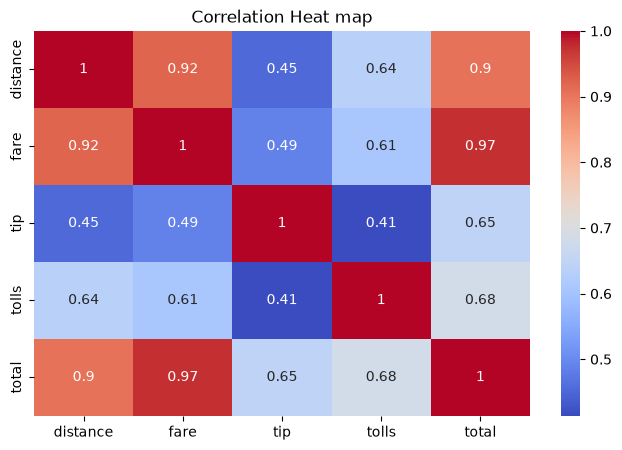

In [8]:
plt.figure(figsize=(8,5))
sns.heatmap(correlation,annot=True,cmap='coolwarm')
plt.title('Correlation Heat map') 
plt.show()

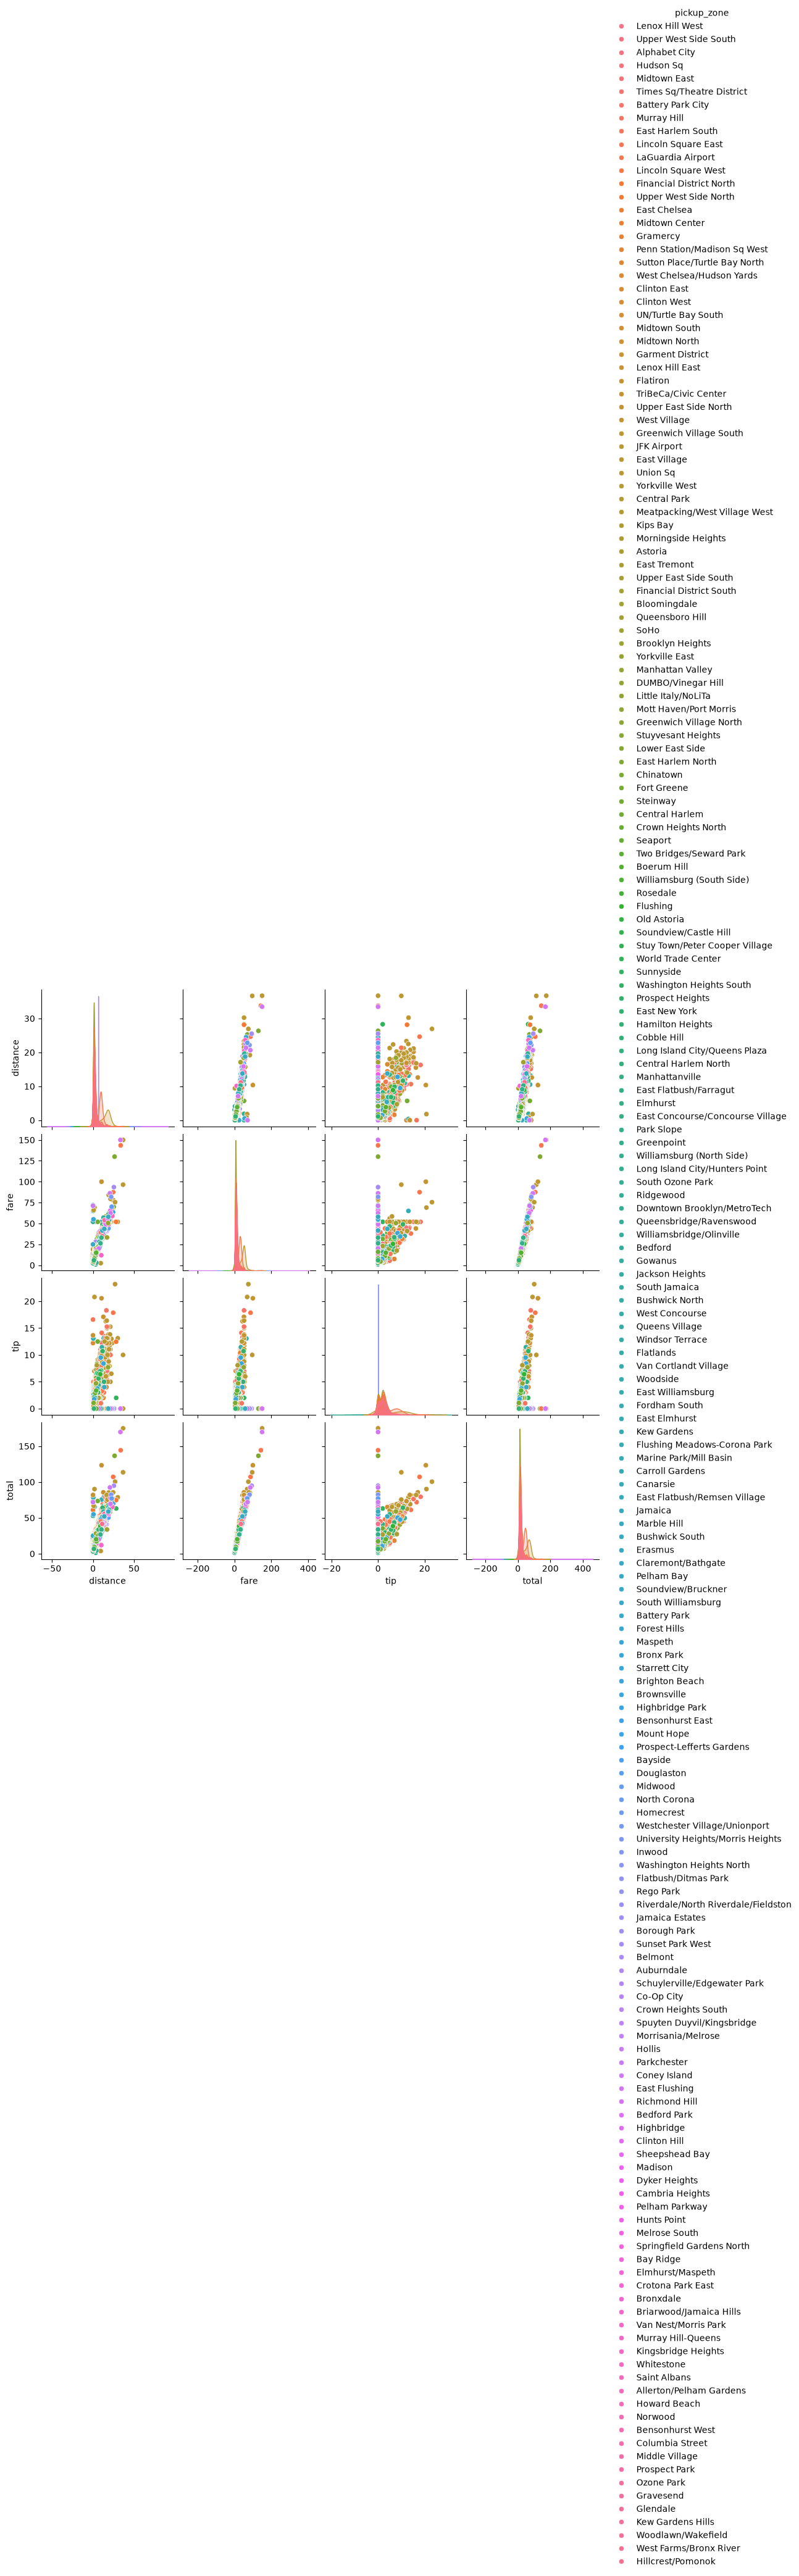

In [9]:
sns.pairplot(df[['distance','fare','tip','total','pickup_zone']],hue='pickup_zone')

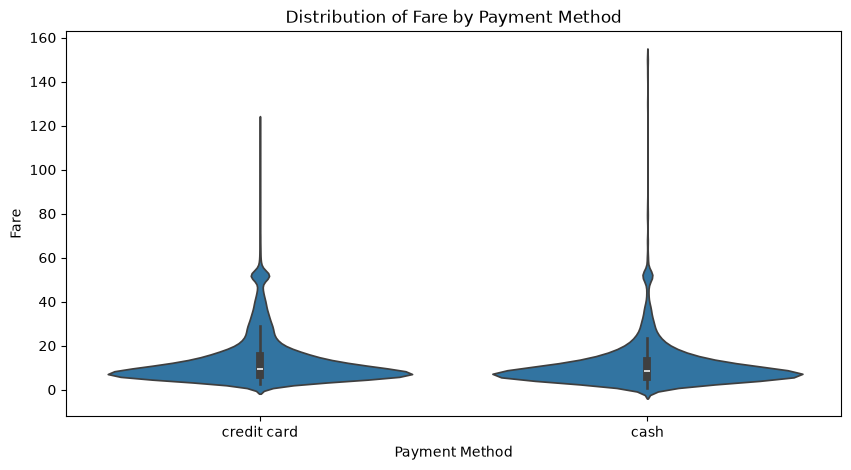

In [10]:
plt.figure(figsize=(10,5))
sns.violinplot(x='payment',y='fare',data=df)
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.title('Distribution of Fare by Payment Method')
plt.show()